In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv("../data/raw/housing.csv")

In [3]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
for col in df.select_dtypes(include=np.number).columns:
    df[col]=df[col].fillna(df[col].median())

In [5]:
df.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [6]:
df.dtypes

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object

In [7]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,536.838857,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,419.391878,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,297.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,643.250000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [8]:
Q1 = df["median_house_value"].quantile(0.25) 
Q3 = df["median_house_value"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 *IQR 
upper = Q3 + 1.5 *IQR

print("Q1:", Q1) 
print("Q3:", Q3)
print("Lower Bond:", lower) 
print("Upper Bond:", upper) 

Q1: 119600.0
Q3: 264725.0
Lower Bond: -98087.5
Upper Bond: 482412.5


In [9]:
outliers = (df["median_house_value"] < lower) | (df["median_house_value"] > upper)
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Total Outliers:", outliers.sum())

Q1: 119600.0
Q3: 264725.0
IQR: 145125.0
Total Outliers: 1071


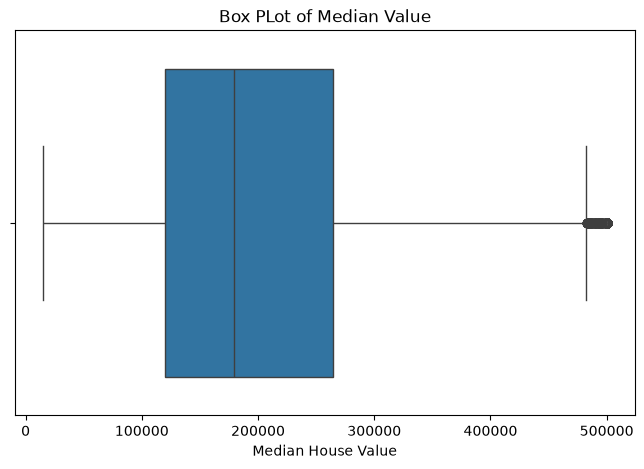

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=[8, 5])
sns.boxplot(x=df['median_house_value'])
plt.title("Box PLot of Median Value")
plt.xlabel("Median House Value")
plt.show()

In [11]:
print(df["median_house_value"].sort_values(ascending=False).head(10))

5253    500001.0
5254    500001.0
5255    500001.0
5256    500001.0
5257    500001.0
5258    500001.0
5259    500001.0
5260    500001.0
5261    500001.0
5262    500001.0
Name: median_house_value, dtype: float64


In [14]:
import os
os.makedirs("../data/processed", exist_ok=True)
df.to_csv("../data/processed/cleaned_housing.csv", index=False)   